# 03. Polynomial Regression

**Project** · Vehicle Braking Distance Prediction  
**Problem type** · Regression

This dataset is synthetic and designed for education. Keep its predictions within the exercise. Any real-world financial, medical, safety, educational or employment decision requires independent evidence and validation.

Start with Sections 1–9 for your first model. Then try parameter tuning and the interview exercises. Run the code cells in order because each step uses results from earlier cells.

## 1. Introduction

Polynomial regression models curved relationships using powers of the inputs as features. Doubling speed in a simplified constant-deceleration example can roughly quadruple the braking distance. A straight line imposes a constant slope, while a quadratic lets the slope change.

By the end, you can implement the pipeline, explain how it predicts and use holdout results to identify where it struggles.

## 2. Understand the Dataset

Distance is 0.8 + 0.0051 × speed², plus Gaussian noise with standard deviation 1.3 + 0.045 × speed in metres, floored at 0.4 m. This is an illustrative relationship without reaction distance, road conditions or vehicle-specific physics.

| Column | Type | Units or values | Meaning |
| --- | --- | --- | --- |
| `speed_kmh` | decimal | km/h | Vehicle speed when braking begins |
| `braking_distance_m` | decimal | m | Observed continuous outcome |

**Independent variables (X)** · `speed_kmh`.

**Dependent variable (y)** · `braking_distance_m` is the continuous quantity to predict in m. The preview shows the first 10 rows, dimensions and stored types. Blank features, where present, are intentional.

In [2]:
import os
os.environ.setdefault("OPENBLAS_NUM_THREADS", "2")
os.environ.setdefault("OMP_NUM_THREADS", "2")

from pathlib import Path
import pandas as pd
from IPython.display import display

csv_name = "03_vehicle_braking.csv"
csv_path = Path("../datasets") / csv_name

# Also look in the project folder or the location used for Colab uploads.
if not csv_path.is_file():
    csv_path = Path("datasets") / csv_name
if not csv_path.is_file():
    csv_path = Path("Machine_Learning_Complete_Guide/datasets") / csv_name
if not csv_path.is_file():
    csv_path = Path(csv_name)

df = pd.read_csv(csv_path, keep_default_na=False, na_values=[""])
print("Dataset shape:", df.shape)
display(df.head(10))
display(df.dtypes)

Dataset shape: (1500, 2)


,speed_kmh,braking_distance_m
0,22.84,2.99
1,93.12,43.84
2,22.90,4.41
3,50.13,14.69
4,88.79,38.73
5,35.58,10.90
6,95.27,47.32
7,69.86,26.90
8,76.09,32.82
9,73.51,34.17


speed_kmh             float64
braking_distance_m    float64
dtype: object

## 3. Mathematical Understanding

For raw speed $s$, a quadratic has the equivalent form $\hat d=b+w_1s+w_2s^2$, where $\hat d$ is predicted distance, $b$ is the intercept, and $w_1,w_2$ weight speed and speed squared. Fit these weights by minimizing $\sum_i(d_i-\hat d_i)^2$ over training examples $i$ with observed distances $d_i$. The code standardizes speed before taking powers to reduce numerical scale differences. A quadratic in standardized speed still represents a quadratic in raw speed.

If $b=0.8$, $w_1=0$ and $w_2=0.005$, then $s=40$ gives $8.8$ m and $s=80$ gives $32.8$ m. The slope of the raw-speed model is $w_1+2w_2s$, or $0.4$ metres per additional km/h locally at $s=40$.

[scikit-learn user guide](https://scikit-learn.org/stable/modules/preprocessing.html#generating-polynomial-features)

## 4. Working Principle

Map each raw speed to a short feature row containing standardized speed and its square. Fit ordinary least squares to those columns. At prediction time apply exactly the same mapping to the new speed, multiply by the learned weights, and add the intercept.

| Input | Mapped term | Prediction |
| --- | --- | --- |
| 40 km/h | Speed² = 1,600 | 8.8 m |
| 80 km/h | Speed² = 6,400 | 32.8 m |

**Workflow diagram**

`Raw input` → `Scaled speed and its powers` → `Fits a linear model over polynomial features` → `Estimate in m`.

## 5. Dataset Exploration

The first and last rows verify parsing. Shape and info reveal size, stored types and non-missing counts. Summary statistics show typical values, ranges and spread. Missingness and duplicate counts identify possible cleanup needs. The target plot shows the range and shape of the outcome. Feature plots show variation. Pearson correlation measures linear association. Watch for nonlinear trends even if a linear association is present. The features and evaluation design are fixed before modeling.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
TARGET = "braking_distance_m"
FEATURES = ["speed_kmh"]
NUMERIC = ["speed_kmh"]
CATEGORICAL = []
SEED = 42

In [4]:
df.info()
display(df.head())
display(df.tail())
display(df.describe(include="all").T)
display(pd.DataFrame({"Missing": df.isna().sum(), "Missing %": 100 * df.isna().mean()}).round(1))
print("Exact duplicate rows:", df.duplicated().sum())
print("Repeated feature rows:", df.duplicated(subset=FEATURES).sum())

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 2 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   speed_kmh           1500 non-null   float64
 1   braking_distance_m  1500 non-null   float64
dtypes: float64(2)
memory usage: 23.6 KB


,speed_kmh,braking_distance_m
0,22.84,2.99
1,93.12,43.84
2,22.90,4.41
3,50.13,14.69
4,88.79,38.73


,speed_kmh,braking_distance_m
1495,26.12,4.64
1496,93.27,44.87
1497,85.77,32.91
1498,30.70,7.59
1499,53.76,9.99


,count,mean,std,min,25%,50%,75%,max
speed_kmh,1500.0,70.428133,31.838822,15.28,42.3875,70.250,97.3200,124.89
braking_distance_m,1500.0,31.113747,23.517155,0.40,10.1475,25.815,48.3925,92.09


,Missing,Missing %
speed_kmh,0,0.0
braking_distance_m,0,0.0


Exact duplicate rows: 0
Repeated feature rows: 100


### Plot the target

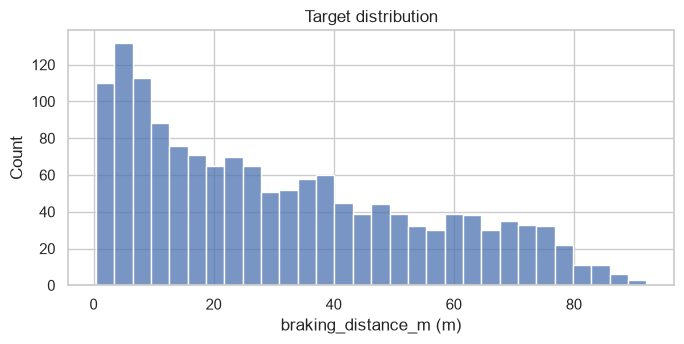

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.6))
sns.histplot(data=df, x=TARGET, bins=30, ax=ax)
ax.set_xlabel("braking_distance_m (m)")
ax.set_title("Target distribution")
fig.tight_layout()
plt.show()

### Look at the input features

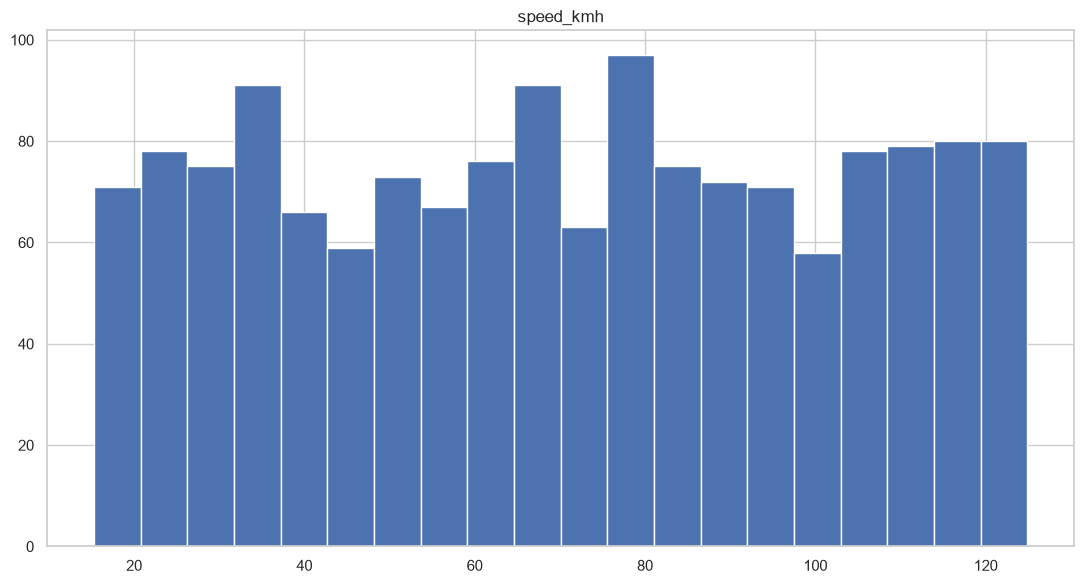

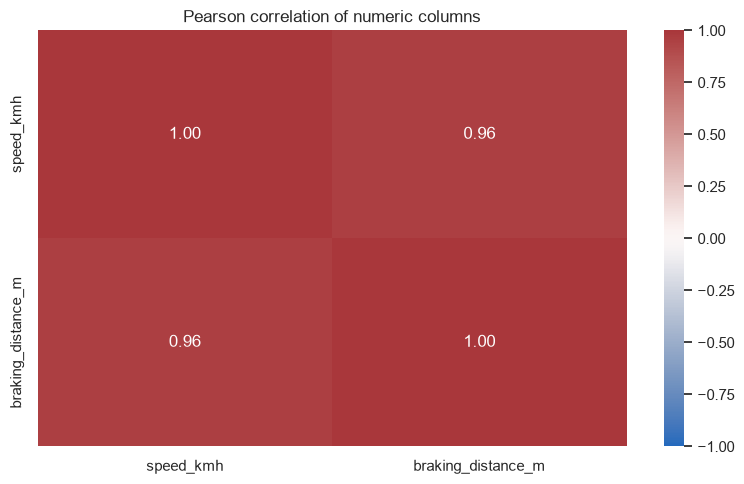

In [6]:
df[NUMERIC].hist(figsize=(11, 6), bins=20)
plt.tight_layout()
plt.show()

correlation_columns = NUMERIC + [TARGET]
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(df[correlation_columns].corr(), annot=True, fmt=".2f", cmap="vlag",
            center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Pearson correlation of numeric columns")
fig.tight_layout()
plt.show()

## 6. Data Preprocessing

Select the input columns and target explicitly. A seeded random split suits these independently generated rows. The numeric branch fills blanks using training medians. This dataset has no categorical predictors. StandardScaler uses training means and standard deviations to make numeric magnitudes comparable. The pipeline fits each preprocessing step after the split and repeats it in each training fold.

Exact and feature-only duplicate counts are listed above. Identical measurements with distinct outcomes can represent legitimate observations.

### 1. Choose the inputs and target

In [7]:
# X contains the inputs. y contains the answer for each row.
X = df[FEATURES]
y = df[TARGET]

### 2. Split the rows into training and test sets

In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 1200
Test rows: 300


### 3. Prepare the columns

The next cell sets up the cleaning steps. They learn their values later, when you fit the model.

In [9]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Fill blank numbers, then put numeric columns on comparable scales.
numeric_preprocess = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

preprocess = ColumnTransformer(
    [
        ("numeric", numeric_preprocess, NUMERIC),
    ],
    verbose_feature_names_out=False,
)

## 7. Model Implementation

`degree=2` includes the first and second powers. `include_bias=False` avoids adding a redundant constant feature because the estimator fits its own intercept. The exercise compares degrees 1, 2, 3 and 7 and uses Ridge on some candidates to show coefficient shrinkage.

- The estimator import provides the algorithm implementation.
- `Pipeline` joins preprocessing and the model in execution order.
- `fit(X_train, y_train)` learns transformations and parameters from training rows.
- `predict(...)` applies the fitted steps to new rows. The first holdout row gives a preview before scoring the entire split.

### Create the model

In [10]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import PolynomialFeatures

estimator = LinearRegression()
model = Pipeline([
    ("preprocess", preprocess),
    ("features", PolynomialFeatures(degree=2, include_bias=False)),
    ("model", estimator),
])

### Fit on the training rows

In [11]:
# Learn from the training rows.
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('features', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](1,)",['speed_kmh']
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,1
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[st

### Predict on the test rows

In [12]:
# Predict using the held-out inputs.
predictions = model.predict(X_test)
display(X_test.head(1))
print(f"Example prediction: {predictions[0]:,.2f} m")

,speed_kmh
1116,116.49


Example prediction: 69.70 m


## 8. Model Evaluation

Let $y_i$ be the actual test value for row $i$, $\hat y_i$ its prediction, $e_i=y_i-\hat y_i$ its residual, $n$ the number of test rows and $\bar y$ the test target mean.

| Metric | Formula | Interpretation |
| --- | --- | --- |
| Mean absolute error | $\mathrm{MAE}=n^{-1}\sum_i\lvert e_i\rvert$ | Mean absolute miss in the target unit. Lower is better. |
| Mean squared error | $\mathrm{MSE}=n^{-1}\sum_i e_i^2$ | Mean squared miss in squared units. It puts more weight on large errors. Lower is better. |
| Root mean squared error | $\mathrm{RMSE}=\sqrt{\mathrm{MSE}}$ | Error on the target scale that emphasizes large misses. Lower is better. |
| Coefficient of determination | $R^2=1-\sum_i e_i^2/\sum_i(y_i-\bar y)^2$ | Higher is better. One is a perfect fit, zero matches the squared error of the test mean, and negative means more error than that reference. |

The baseline predicts the **training** target mean, so its test R² may be slightly negative. Compare MAE and RMSE to it in the table below.

**Target unit** · m.

In [13]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

initial_metrics = {
    "MAE": mean_absolute_error(y_test, predictions),
    "MSE": mean_squared_error(y_test, predictions),
    "RMSE": root_mean_squared_error(y_test, predictions),
    "R²": r2_score(y_test, predictions),
}
display(pd.Series(initial_metrics, name="Test score").round(3))

MAE      3.552
MSE     21.683
RMSE     4.657
R²       0.957
Name: Test score, dtype: float64

### Compare with a simple baseline

In [14]:
# A baseline predicts the mean training target for every row.
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)

baseline_metrics = {
    "MAE": mean_absolute_error(y_test, baseline_predictions),
    "MSE": mean_squared_error(y_test, baseline_predictions),
    "RMSE": root_mean_squared_error(y_test, baseline_predictions),
    "R²": r2_score(y_test, baseline_predictions),
}
display(pd.DataFrame([baseline_metrics, initial_metrics], index=["Baseline", "Model"]).round(3))

,MAE,MSE,RMSE,R²
Baseline,19.197,509.818,22.579,-0.000
Model,3.552,21.683,4.657,0.957


## 9. Visualizations

Compare estimated and measured outcomes against the 45-degree line. A point above that line is an overestimate. In the residual panel, points above zero are underestimates. A systematic curve suggests missing structure, and widening scatter suggests changing error spread.

The curve should follow the increase in slope more closely than the straight line. Wider scatter at high speed reflects the changing noise level in the generator. Both fits use the same training split.

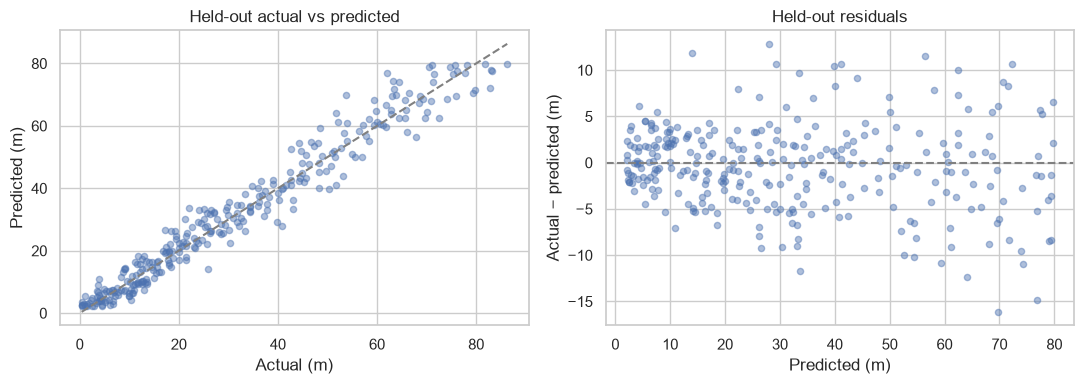

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
limits = [min(y_test.min(), predictions.min()), max(y_test.max(), predictions.max())]
axes[0].scatter(y_test, predictions, s=20, alpha=0.45)
axes[0].plot(limits, limits, color="grey", linestyle="--")
axes[0].set(xlabel="Actual (m)", ylabel="Predicted (m)", title="Held-out actual vs predicted")
axes[1].scatter(predictions, y_test - predictions, s=20, alpha=0.45)
axes[1].axhline(0, color="grey", linestyle="--")
axes[1].set(xlabel="Predicted (m)", ylabel="Actual − predicted (m)", title="Held-out residuals")
fig.tight_layout()
plt.show()

### A closer look at this model

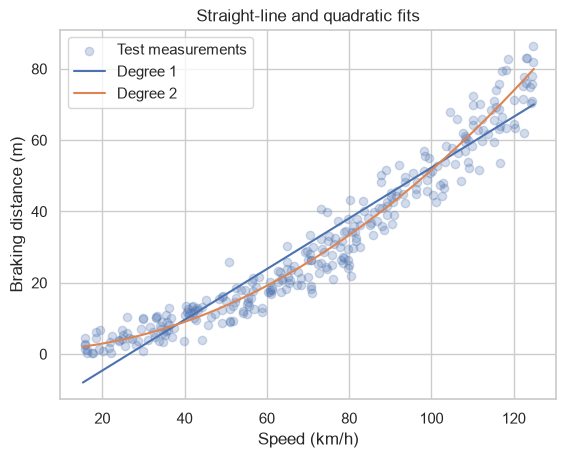

In [16]:
from sklearn.base import clone

straight_line = clone(model).set_params(features__degree=1).fit(X_train, y_train)
speed_grid = pd.DataFrame({"speed_kmh": np.linspace(X_train["speed_kmh"].min(), X_train["speed_kmh"].max(), 200)})
fig, ax = plt.subplots()
ax.scatter(X_test["speed_kmh"], y_test, alpha=0.25, label="Test measurements")
ax.plot(speed_grid["speed_kmh"], straight_line.predict(speed_grid), label="Degree 1")
ax.plot(speed_grid["speed_kmh"], model.predict(speed_grid), label="Degree 2")
ax.set(xlabel="Speed (km/h)", ylabel="Braking distance (m)", title="Straight-line and quadratic fits")
ax.legend()
plt.show()

## 10. Hyperparameter Tuning

GridSearchCV tries the grid with three shuffled folds within the training data. Each candidate gets a freshly fitted pipeline per fold. Rank by lowest RMSE. The scorer negates RMSE so that the best score ranks first. `refit=True` fits the winner on all training rows. Use the CV ranks to choose parameters and the holdout to report performance.

`degree=2` includes the first and second powers. `include_bias=False` avoids adding a redundant constant feature because the estimator fits its own intercept. The exercise compares degrees 1, 2, 3 and 7 and uses Ridge on some candidates to show coefficient shrinkage.

[GridSearchCV documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)

### Set up the candidate settings

In [17]:
from sklearn.model_selection import GridSearchCV, KFold

param_grid = [{"features__degree": [1, 2, 3, 7], "model": [LinearRegression()]},
 {"features__degree": [2, 3, 7], "model": [Ridge()], "model__alpha": [0.1, 10]}]
validation = KFold(n_splits=3, shuffle=True, random_state=SEED)
search = GridSearchCV(model, param_grid, scoring="neg_root_mean_squared_error", cv=validation,
                      refit=True, n_jobs=1, error_score="raise")

### Search using training rows

In [18]:
search.fit(X_train, y_train)
tuned_model = search.best_estimator_
results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
results["Mean fold RMSE"] = -results["mean_test_score"]
print("Best training-CV parameters:", search.best_params_)
display(results[["rank_test_score", "Mean fold RMSE", "std_test_score", "params"]].head().round(3))

Best training-CV parameters: {'features__degree': 7, 'model': Ridge(), 'model__alpha': 0.1}


,rank_test_score,Mean fold RMSE,std_test_score,params
8,1,4.595,0.234,"{'features__degree': 7, 'model': Ridge(), 'mod..."
3,2,4.595,0.234,"{'features__degree': 7, 'model': LinearRegress..."
1,3,4.608,0.220,"{'features__degree': 2, 'model': LinearRegress..."
4,4,4.608,0.219,"{'features__degree': 2, 'model': Ridge(), 'mod..."
6,5,4.609,0.220,"{'features__degree': 3, 'model': Ridge(), 'mod..."


### Compare the models on the test set

In [19]:
tuned_predictions = tuned_model.predict(X_test)

tuned_metrics = {
    "MAE": mean_absolute_error(y_test, tuned_predictions),
    "MSE": mean_squared_error(y_test, tuned_predictions),
    "RMSE": root_mean_squared_error(y_test, tuned_predictions),
    "R²": r2_score(y_test, tuned_predictions),
}
comparison = pd.DataFrame(
    [baseline_metrics, initial_metrics, tuned_metrics],
    index=["Baseline", "First model", "Tuned model"],
)
display(comparison.round(3))

,MAE,MSE,RMSE,R²
Baseline,19.197,509.818,22.579,-0.000
First model,3.552,21.683,4.657,0.957
Tuned model,3.574,22.024,4.693,0.957


## 11. Real-World Prediction

Pass three new examples to the CV-selected pipeline. Read the estimates in m and compare the scenarios to see how the fitted model responds.

### Enter three new examples

In [20]:
examples = pd.DataFrame([
    [35],
    [65],
    [105],
], columns=FEATURES)
display(examples)

,speed_kmh
0,35
1,65
2,105


### Make predictions

In [21]:
sample_inputs = examples
prediction_model = tuned_model
sample_predictions = prediction_model.predict(sample_inputs)
example_output = examples.copy()
example_output["Scenario"] = ["Lower speed within the observed range","Mid-range speed","Higher speed within the observed range"]
example_output["Predicted braking_distance_m (m)"] = sample_predictions.round(2)
display(example_output)

,speed_kmh,Scenario,Predicted braking_distance_m (m)
0,35,Lower speed within the observed range,7.22
1,65,Mid-range speed,22.59
2,105,Higher speed within the observed range,56.77


## 12. Limitations and Advantages

Low-degree polynomials are interpretable and inexpensive for a small input set. A straight line may underfit curvature, while high degree can model noise and behave erratically near the edges. The assumed polynomial form applies everywhere and does not enforce monotonicity or physical bounds. Use a low degree for a smooth relationship in a measured range. Avoid relying on a high-degree fit for extrapolation.

## 13. Interview Preparation

### A. 30-second explanation

> I modeled braking distance from speed using polynomial features and linear regression. A quadratic can learn a changing slope while still fitting linear coefficients. I compared the fitted curve with a training-only straight-line fit and cross-validated several polynomial degrees.

### B. 90-second technical explanation

> I modeled braking distance from speed using polynomial features and linear regression. A quadratic can learn a changing slope while still fitting linear coefficients. I compared the fitted curve with a training-only straight-line fit and cross-validated several polynomial degrees. My target was braking distance m, and the inputs were speed kmh. Map each raw speed to a short feature row containing standardized speed and its square. Fit ordinary least squares to those columns. At prediction time apply exactly the same mapping to the new speed, multiply by the learned weights, and add the intercept. I held out 20% of the rows and fitted preprocessing within each training fold. I measured MAE in m and RMSE to see how much larger errors mattered. I compared the model with a training-mean predictor and inspected residuals. The inputs and labels were generated for teaching, so the holdout performance describes this exercise. For real data I would confirm which inputs are available at prediction time and build a split that reflects where the model will be used.

### C. Ten technical questions

1. **Why is it still linear regression?** The prediction is linear in the unknown weights after the feature mapping.
2. **What does degree one do?** It keeps the basic linear relationship.
3. **Why standardize before building powers?** It keeps magnitudes more manageable, especially for high degrees.
4. **Why set include_bias to False?** The separate fitted intercept already supplies a constant.
5. **What happens outside the observed speed range?** High powers can dominate and extrapolated predictions may be implausible.
6. **How do you choose degree?** Compare a small set using training cross-validation and consider domain knowledge.
7. **How can Ridge help?** It shrinks large coefficients and can reduce variance in flexible feature sets.
8. **How does the feature count grow with many inputs?** Powers and interactions increase the number combinatorially.
9. **What does a residual pattern shaped like a U indicate?** The model may miss curvature.
10. **What does increasing residual spread at higher speed suggest?** Noise variance changes with speed.

### D. Five scenario questions

1. **A seventh-degree curve lowers training error. Which would you choose?** Check validation RMSE, favouring simpler curves when performance is similar.
2. **A straight line overestimates low and high speeds. What next?** Inspect the curve and try a quadratic for systematic curvature.
3. **You must predict at 190 km/h. What changes?** Collect data in that range and use a physically motivated model if the use case requires it.
4. **You add vehicle mass as an input. What extra features appear?** With degree two, a mass square and mass-by-speed interaction appear.
5. **Predictions must increase with speed. How can you enforce this?** Use a constrained or physics-informed model and verify monotonicity over the operating range.

### E. Three common mistakes

- Choosing a flexible degree by training error. Use validation.
- Fitting a new scaling transform when predicting. Reuse the pipeline.
- Reporting this toy relationship as a stopping-distance calculator. Keep it as a braking-distance demonstration.

### F. Complete project explanation

Use the measured scores in a short project walkthrough. Start with the problem, explain the pipeline and close with what the evaluation can support. This cell inserts results from the current run.

In [22]:
from IPython.display import Markdown

summary = (
    "I built a supervised regression project for vehicle braking distance prediction using Polynomial Regression. I generated 1,500 synthetic observations and used speed kmh to predict braking distance m. I used a holdout and a preprocessing pipeline fitted within training folds. I compared the selected estimator with a simple baseline. "
    f"On the holdout, the CV-selected model achieved MAE {tuned_metrics['MAE']:,.2f} m, "
    f"compared with {baseline_metrics['MAE']:,.2f} m for the training-mean baseline. "
    f"Its RMSE was {tuned_metrics['RMSE']:,.2f} m. "
    "I plotted the quadratic and straight-line fits together to show where a changing slope helped. These results apply to the synthetic data and should be validated on representative observations before practical use."
)
display(Markdown("> " + summary))

> I built a supervised regression project for vehicle braking distance prediction using Polynomial Regression. I generated 1,500 synthetic observations and used speed kmh to predict braking distance m. I used a holdout and a preprocessing pipeline fitted within training folds. I compared the selected estimator with a simple baseline. On the holdout, the CV-selected model achieved MAE 3.57 m, compared with 19.20 m for the training-mean baseline. Its RMSE was 4.69 m. I plotted the quadratic and straight-line fits together to show where a changing slope helped. These results apply to the synthetic data and should be validated on representative observations before practical use.